## Занятие 5. Описательная статистика

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
df = pd.read_csv('customer_data.csv')

### Задание 1. Общая описательная статистика

In [2]:
df.head()

,CustomerID,Age,AnnualIncome,MonthlySpending,Region,Gender
0,C0001,38,64464,16210,South,Male
1,C0002,48,48159,14159,North,Male
2,C0003,22,57139,17516,South,Female
3,C0004,32,32944,4080,East,Female
4,C0005,38,43046,11069,East,Female


In [3]:
df[['Age', 'AnnualIncome', 'MonthlySpending']].describe()

,Age,AnnualIncome,MonthlySpending
count,150.000000,150.000000,150.000000
mean,38.293333,48814.453333,12820.053333
std,11.389708,49185.385292,8451.653866
min,18.000000,20000.000000,1000.000000
25%,29.250000,24297.250000,6643.750000
50%,38.000000,38480.500000,11195.500000
75%,47.750000,57543.750000,17492.500000
max,65.000000,450000.000000,40245.000000


In [4]:
for col in ['Age', 'AnnualIncome', 'MonthlySpending']:
    print(f"{col}:")
    print(f"  Среднее = {df[col].mean():>12,.2f}")
    print(f"  Медиана = {df[col].median():>12,.2f}")
    print(f"  Skew    = {stats.skew(df[col], bias=False):>12.3f}")
    print(f"  Kurt    = {stats.kurtosis(df[col], bias=False):>12.3f}")
    print()

Age:
  Среднее =        38.29
  Медиана =        38.00
  Skew    =        0.167
  Kurt    =       -0.737

AnnualIncome:
  Среднее =    48,814.45
  Медиана =    38,480.50
  Skew    =        5.876
  Kurt    =       42.529

MonthlySpending:
  Среднее =    12,820.05
  Медиана =    11,195.50
  Skew    =        0.888
  Kurt    =        0.501



**Вывод:** для AnnualIncome среднее (48 814) заметно выше медианы (38 481), skew = 5.9, kurt = 42.5 — распределение сильно скошено вправо из-за выбросов (максимум 450 000 при медиане ~38 000). Возраст (Age) близок к симметричному.

### Задание 2. Статистика по группам (регионы)

In [5]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

region_stats = df.groupby('Region')['AnnualIncome'].agg(
    mean='mean', median='median', std='std', iqr=iqr
)
region_stats

,mean,median,std,iqr
Region,,,,
East,46083.590909,44895.0,21253.961904,20651.5
North,43848.086957,36042.5,24791.901154,33173.0
South,55556.905660,31733.0,76314.725692,32751.0
West,46441.413793,42884.0,24348.604946,27354.0


**Вывод:** самый высокий средний доход — в South (55 557), но там же огромный разброс (std ≈ 76 315) из-за выбросов. Самый равномерный доход — в East (std ≈ 21 254, наименьший IQR ≈ 20 652). По медиане выше всего East (44 895).

### Задание 3. Анализ распределения (асимметрия и эксцесс)

Skew (асимметрия)     = 0.888
Kurtosis (эксцесс)    = 0.501


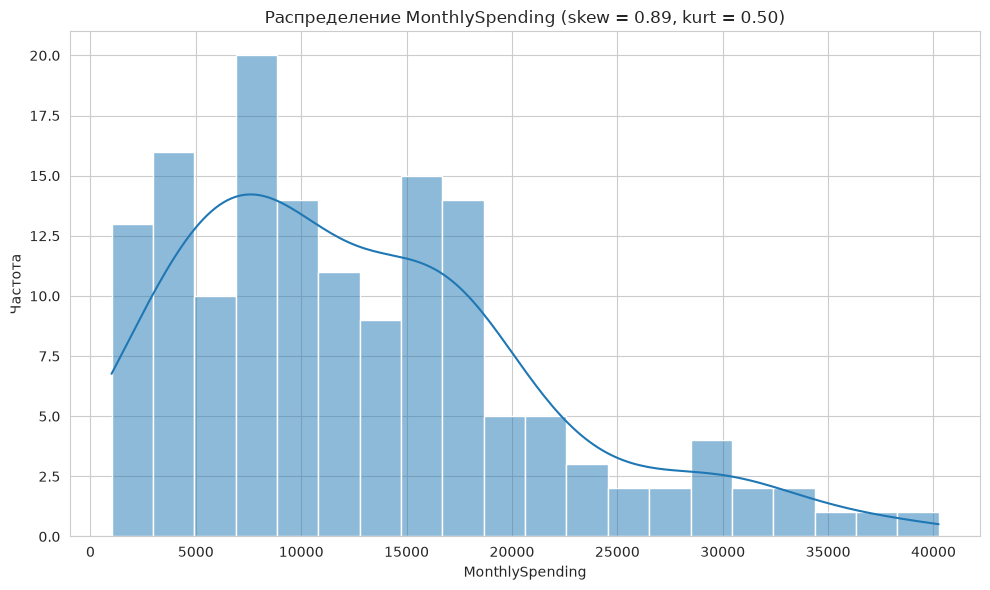

In [6]:
skew_spend = stats.skew(df['MonthlySpending'], bias=False)
kurt_spend = stats.kurtosis(df['MonthlySpending'], bias=False)

print(f"Skew (асимметрия)     = {skew_spend:.3f}")
print(f"Kurtosis (эксцесс)    = {kurt_spend:.3f}")

plt.figure(figsize=(10, 6))
sns.histplot(df['MonthlySpending'], bins=20, kde=True)
plt.title(f'Распределение MonthlySpending (skew = {skew_spend:.2f}, kurt = {kurt_spend:.2f})')
plt.xlabel('MonthlySpending')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

**Вывод:** skew = 0.89 — распределение MonthlySpending умеренно скошено вправо; kurt = 0.5 — лёгкие тяжёлые хвосты, но выраженных выбросов нет. Это соответствует экономической логике: расходы не бывают отрицательными, но у более обеспеченных клиентов встречаются большие траты, растягивающие правый хвост.

### Задание 4. Перцентили и сравнение групп (пол)

In [7]:
percentiles = df.groupby('Gender')['AnnualIncome'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
percentiles.columns = ['10%', '25%', '50% (медиана)', '75%', '90%']
percentiles

,10%,25%,50% (медиана),75%,90%
Gender,,,,,
Female,20000.0,24530.0,38613.0,57453.5,68501.4
Male,20000.0,22732.0,38348.0,56566.5,80938.8


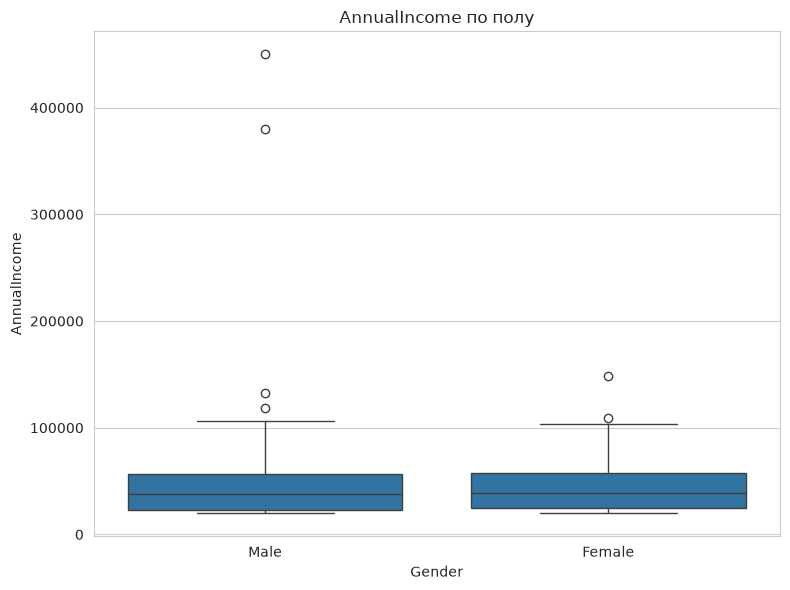

In [8]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Gender', y='AnnualIncome', data=df)
plt.title('AnnualIncome по полу')
plt.tight_layout()
plt.show()

**Вывод:** медианы дохода у мужчин и женщин практически одинаковы (38 348 vs 38 613), но правый хвост у мужчин длиннее: 90-й перцентиль у мужчин 80 939 против 68 501 у женщин — среди мужчин больше высоких доходов.

### Задание 5. Визуализация распределений всех трёх числовых признаков

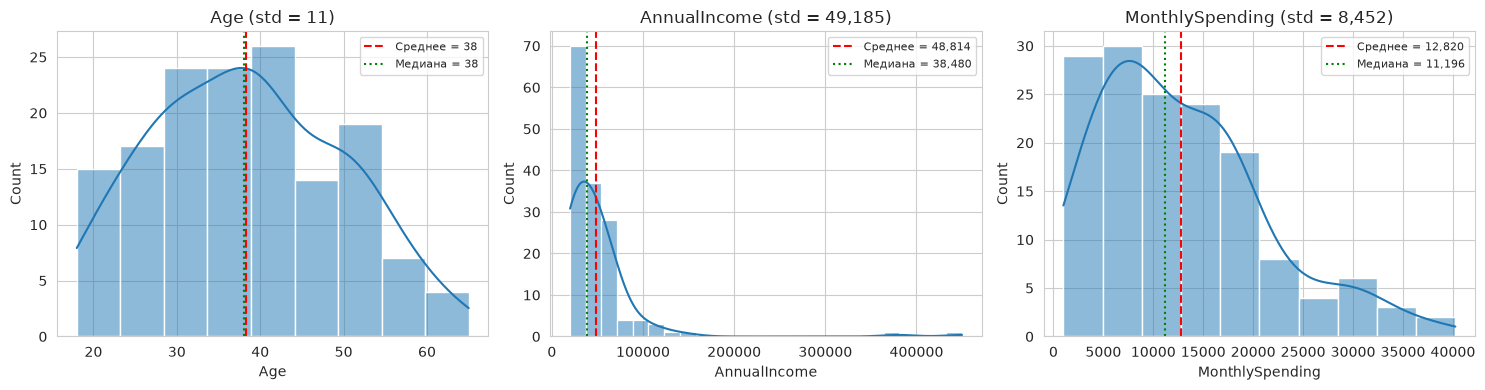

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age', 'AnnualIncome', 'MonthlySpending']):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Среднее = {df[col].mean():,.0f}')
    ax.axvline(df[col].median(), color='green', linestyle=':', linewidth=1.5, label=f'Медиана = {df[col].median():,.0f}')
    ax.set_title(f'{col} (std = {df[col].std():,.0f})')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Вывод:** ближе всего к нормальному Age (skew = 0.17, но плосковершинное, kurt = -0.7). AnnualIncome сильно скошен вправо (skew = 5.9) из-за выбросов, MonthlySpending умеренно скошен вправо (skew = 0.89).